# Homework 8.2 - Part I

## Forward Simulation

The model is

$$
dX_t
=
a(-X_t+L_t)\,dt
+
\sigma\,dW_t
$$

and

$$
dL_t
=
-\kappa
\frac{|X_t|}
{1+\eta|L_t|}
\,dt.
$$

The perceived deviation observed by the controller is

$$
Y_t=X_t-L_t.
$$

We use the parameter values suggested in the assignment:

$$
a=0.5,
\qquad
\kappa=0.05,
\qquad
\sigma=0.2,
\qquad
\eta=1.
$$

The initial state is

$$
X_0=1,
\qquad
L_0=0.
$$

## Numerical design

Euler-Maruyama is used with

$$
\Delta t=0.01,
\qquad
T=50.
$$

We simulate 5000 realizations with a fixed random seed.

The Euler updates are

$$
X_{n+1}
=
X_n
+
a(-X_n+L_n)\Delta t
+
\sigma\sqrt{\Delta t}Z_n
$$

and

$$
L_{n+1}
=
L_n
-
\kappa
\frac{|X_n|}
{1+\eta|L_n|}
\Delta t,
$$

where

$$
Z_n\sim N(0,1).
$$

Only a small fixed set of sample paths is stored in full. Ensemble summaries are stored at a coarser plotting grid to keep memory use modest.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw8_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw8_2"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

A = 0.5
KAPPA = 0.05
SIGMA = 0.2
ETA = 1.0

X0 = 1.0
L0 = 0.0

DT = 0.01
T = 50.0
N_PATHS = 5000
SEED = 63821

N_SAMPLE_PATHS = 20
SUMMARY_EVERY = 10

N_STEPS = int(
    round(
        T / DT
    )
)

CONFIG = {
    "a": A,
    "kappa": KAPPA,
    "sigma": SIGMA,
    "eta": ETA,
    "x0": X0,
    "l0": L0,
    "dt": DT,
    "T": T,
    "n_paths": N_PATHS,
    "seed": SEED,
    "summary_every": SUMMARY_EVERY,
}

config_path = (
    DATA_DIR
    / "hw8_2_configuration.json"
)

config_path.write_text(
    json.dumps(
        CONFIG,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    json.dumps(
        CONFIG,
        indent=2,
    )
)

{
  "a": 0.5,
  "kappa": 0.05,
  "sigma": 0.2,
  "eta": 1.0,
  "x0": 1.0,
  "l0": 0.0,
  "dt": 0.01,
  "T": 50.0,
  "n_paths": 5000,
  "seed": 63821,
  "summary_every": 10
}


In [2]:
def F(l_value, x_value):
    return (
        np.abs(
            x_value
        )
        / (
            1.0
            + ETA
            * np.abs(
                l_value
            )
        )
    )


rng = np.random.default_rng(
    SEED
)

x = np.full(
    N_PATHS,
    X0,
    dtype=float,
)

l = np.full(
    N_PATHS,
    L0,
    dtype=float,
)

sample_x = np.empty(
    (
        N_SAMPLE_PATHS,
        N_STEPS + 1,
    ),
    dtype=float,
)

sample_l = np.empty_like(
    sample_x
)

sample_x[:, 0] = x[
    :N_SAMPLE_PATHS
]

sample_l[:, 0] = l[
    :N_SAMPLE_PATHS
]

summary_rows = []

def append_summary(
    step,
    x_value,
    l_value,
):
    y_value = (
        x_value
        - l_value
    )

    summary_rows.append({
        "step": step,
        "t": step * DT,
        "x_mean": float(
            np.mean(
                x_value
            )
        ),
        "x_q05": float(
            np.quantile(
                x_value,
                0.05,
            )
        ),
        "x_median": float(
            np.median(
                x_value
            )
        ),
        "x_q95": float(
            np.quantile(
                x_value,
                0.95,
            )
        ),
        "l_mean": float(
            np.mean(
                l_value
            )
        ),
        "l_q05": float(
            np.quantile(
                l_value,
                0.05,
            )
        ),
        "l_median": float(
            np.median(
                l_value
            )
        ),
        "l_q95": float(
            np.quantile(
                l_value,
                0.95,
            )
        ),
        "y_mean": float(
            np.mean(
                y_value
            )
        ),
        "y_q05": float(
            np.quantile(
                y_value,
                0.05,
            )
        ),
        "y_median": float(
            np.median(
                y_value
            )
        ),
        "y_q95": float(
            np.quantile(
                y_value,
                0.95,
            )
        ),
    })


append_summary(
    0,
    x,
    l,
)

max_l_increase = (
    -np.inf
)

innovation_sum = 0.0
innovation_square_sum = 0.0
innovation_count = 0

for step in range(
    1,
    N_STEPS + 1,
):
    z = rng.normal(
        size=N_PATHS
    )

    x_old = x.copy()
    l_old = l.copy()

    drift_x = (
        A
        * (
            -x_old
            + l_old
        )
    )

    x = (
        x_old
        + drift_x * DT
        + SIGMA
        * np.sqrt(
            DT
        )
        * z
    )

    l = (
        l_old
        - KAPPA
        * F(
            l_old,
            x_old,
        )
        * DT
    )

    max_l_increase = max(
        max_l_increase,
        float(
            np.max(
                l
                - l_old
            )
        ),
    )

    innovation_sum += float(
        np.sum(
            z
        )
    )

    innovation_square_sum += float(
        np.sum(
            z**2
        )
    )

    innovation_count += len(
        z
    )

    sample_x[:, step] = x[
        :N_SAMPLE_PATHS
    ]

    sample_l[:, step] = l[
        :N_SAMPLE_PATHS
    ]

    if (
        step
        % SUMMARY_EVERY
        == 0
    ):
        append_summary(
            step,
            x,
            l,
        )


summary = pd.DataFrame(
    summary_rows
)

summary_path = (
    DATA_DIR
    / "part1_ensemble_summary.csv"
)

summary.to_csv(
    summary_path,
    index=False,
)

## Implementation checks

Because

$$
\frac{|X|}
{1+\eta|L|}
\ge 0,
$$

the distortion satisfies

$$
L_{n+1}\le L_n.
$$

With $L_0=0$, all simulated $L_n$ should therefore remain nonpositive.

The standardized Euler innovation should reproduce the generated $Z_n$, so its empirical mean should be close to zero and its variance close to one.

In [3]:
innovation_mean = (
    innovation_sum
    / innovation_count
)

innovation_variance = (
    innovation_square_sum
    / innovation_count
    - innovation_mean**2
)

diagnostics = {
    "max_observed_L_increment": (
        max_l_increase
    ),
    "maximum_final_L": float(
        np.max(
            l
        )
    ),
    "minimum_final_L": float(
        np.min(
            l
        )
    ),
    "innovation_mean": (
        innovation_mean
    ),
    "innovation_variance": (
        innovation_variance
    ),
    "all_final_L_nonpositive": bool(
        np.all(
            l <= 1e-14
        )
    ),
    "all_L_increments_nonpositive": bool(
        max_l_increase
        <= 1e-14
    ),
    "final_x_mean": float(
        np.mean(
            x
        )
    ),
    "final_l_mean": float(
        np.mean(
            l
        )
    ),
    "final_y_mean": float(
        np.mean(
            x - l
        )
    ),
}

diagnostics_path = (
    DATA_DIR
    / "part1_implementation_diagnostics.json"
)

diagnostics_path.write_text(
    json.dumps(
        diagnostics,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    json.dumps(
        diagnostics,
        indent=2,
    )
)

{
  "max_observed_L_increment": -7.264661094907865e-12,
  "maximum_final_L": -0.27855834050903316,
  "minimum_final_L": -1.066285049415831,
  "innovation_mean": 0.00014351699179200584,
  "innovation_variance": 0.9998699897014147,
  "all_final_L_nonpositive": true,
  "all_L_increments_nonpositive": true,
  "final_x_mean": -0.5745770319001227,
  "final_l_mean": -0.6136586570950003,
  "final_y_mean": 0.039081625194877595
}


In [4]:
sample_rows = []

time_full = np.arange(
    N_STEPS + 1
) * DT

for path_index in range(
    N_SAMPLE_PATHS
):
    for step in range(
        N_STEPS + 1
    ):
        sample_rows.append({
            "path_index": (
                path_index
            ),
            "t": time_full[
                step
            ],
            "X": sample_x[
                path_index,
                step,
            ],
            "L": sample_l[
                path_index,
                step,
            ],
            "Y": (
                sample_x[
                    path_index,
                    step,
                ]
                - sample_l[
                    path_index,
                    step,
                ]
            ),
        })


sample_table = pd.DataFrame(
    sample_rows
)

sample_path = (
    DATA_DIR
    / "part1_sample_paths.csv"
)

sample_table.to_csv(
    sample_path,
    index=False,
)

print(
    "Saved:",
    sample_path.resolve(),
)

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.2\data\hw8_2\part1_sample_paths.csv


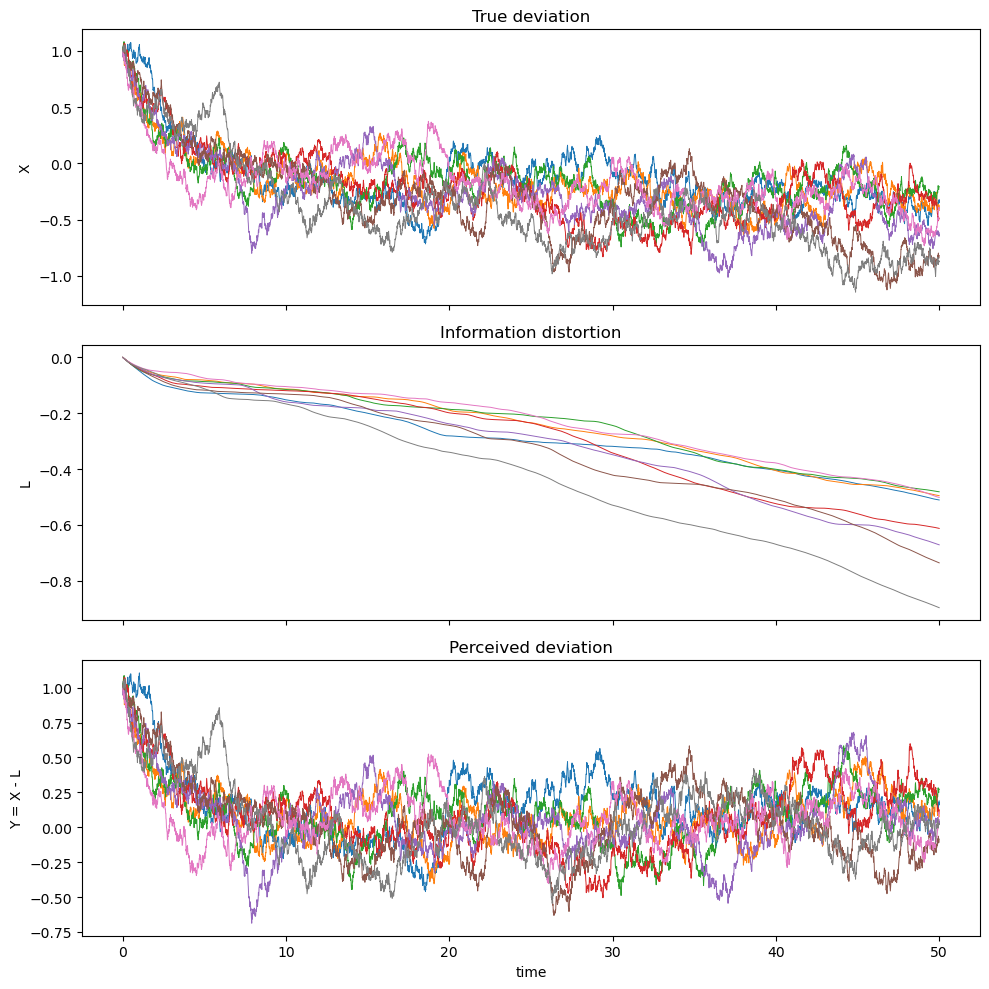

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.2\result images\hw8_2\part1_sample_paths.png


In [5]:
fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 10),
    sharex=True,
)

for path_index in range(
    min(
        8,
        N_SAMPLE_PATHS,
    )
):
    axes[0].plot(
        time_full,
        sample_x[
            path_index
        ],
        linewidth=0.7,
    )

    axes[1].plot(
        time_full,
        sample_l[
            path_index
        ],
        linewidth=0.7,
    )

    axes[2].plot(
        time_full,
        sample_x[
            path_index
        ]
        - sample_l[
            path_index
        ],
        linewidth=0.7,
    )

axes[0].set_ylabel("X")
axes[0].set_title(
    "True deviation"
)

axes[1].set_ylabel("L")
axes[1].set_title(
    "Information distortion"
)

axes[2].set_ylabel("Y = X - L")
axes[2].set_xlabel("time")
axes[2].set_title(
    "Perceived deviation"
)

plt.tight_layout()

path = (
    RESULT_DIR
    / "part1_sample_paths.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print(
    "Saved:",
    path.resolve(),
)

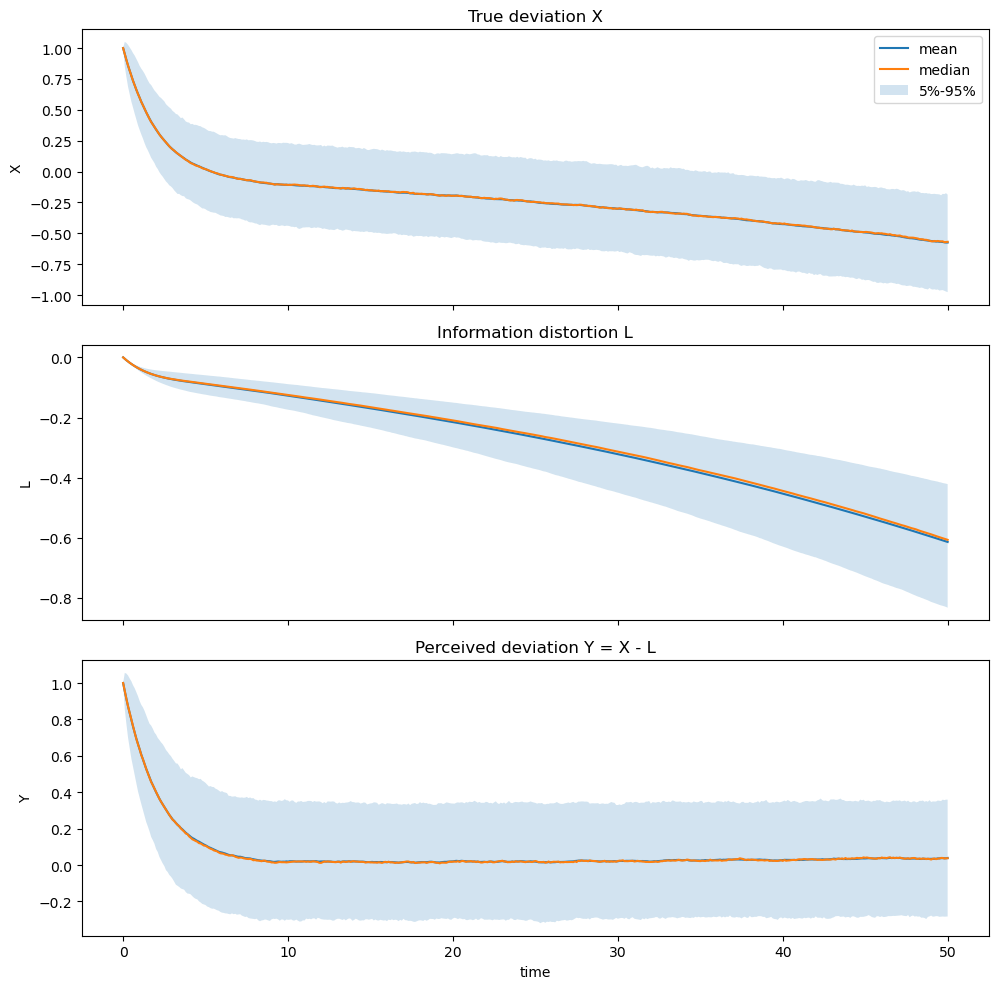

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.2\result images\hw8_2\part1_ensemble_summary.png


In [6]:
fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 10),
    sharex=True,
)

for axis, prefix, title in [
    (
        axes[0],
        "x",
        "True deviation X",
    ),
    (
        axes[1],
        "l",
        "Information distortion L",
    ),
    (
        axes[2],
        "y",
        "Perceived deviation Y = X - L",
    ),
]:
    axis.plot(
        summary["t"],
        summary[
            f"{prefix}_mean"
        ],
        label="mean",
    )

    axis.plot(
        summary["t"],
        summary[
            f"{prefix}_median"
        ],
        label="median",
    )

    axis.fill_between(
        summary["t"],
        summary[
            f"{prefix}_q05"
        ],
        summary[
            f"{prefix}_q95"
        ],
        alpha=0.2,
        label="5%-95%",
    )

    axis.set_ylabel(
        prefix.upper()
    )

    axis.set_title(
        title
    )

axes[-1].set_xlabel(
    "time"
)

axes[0].legend()

plt.tight_layout()

path = (
    RESULT_DIR
    / "part1_ensemble_summary.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print(
    "Saved:",
    path.resolve(),
)

# Part I Interpretation

The true state $X_t$ and perceived state $Y_t=X_t-L_t$ are not the same object.

Since $L_t$ is nonincreasing from zero, it becomes negative and the perceived deviation can differ substantially from the true deviation.

The controller reacts to $Y_t$, not directly to $X_t$.

This distinction is central to Parts IV, V, and VI.